# 2026 Microbial species frequencies and community phenotype
# Data pretreatment

In [3]:
cwd = "/scratch/project_2000746/anthosun/2026FQPH/"

In [6]:
import numpy as np
import pandas as pd
import string
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Simple functions

In [3]:
# smoothing

halfwindow = 3

def summingaround(N, halfwindow = 3):

    AA = N.copy()
    
    for w in np.arange(halfwindow) + 1: # summing over (2*halfwindow)-window
        BB = np.roll(AA, shift=-w, axis=0)
        BB[-w:] = 0
        AA = AA + BB
        BB = np.roll(AA, shift=w, axis=0)
        BB[:w] = 0
        AA = AA + BB
    
    return AA


def smoothing(N, halfwindow = 3):
    
    AA = summingaround(N, halfwindow=halfwindow)
    BB = np.ones(AA.shape)
    BB = summingaround(BB, halfwindow=halfwindow)
    
    return AA / BB

In [4]:
# Compute per-capita derivatives

def to_rhos(T, N):
    
    if len(T.shape) == 1:
        assert T.shape[0] == N.shape[0], "T-array has length {} but N-array has length {}!".format(T.shape[0], N.shape[0])
        for axis in N.shape[1:]:
            T = T[...,np.newaxis]
    else:
        assert T.shape == N.shape, "T-array has shape {} but N-array has shape {}!".format(T.shape, N.shape)
    
    if T.dtype == int:
        T = T.astype(float)
    
    # delta N / N
    
    # forward roll for N
    A = np.roll(N, shift=-1, axis=0)
    A[-1:] = np.nan
    A = A - N
    A[np.isnan(A)] = 0

    # backward roll for N
    B = np.roll(N, shift=1, axis=0)
    B[:1] = np.nan
    B = B - N
    B[np.isnan(B)] = 0
    
    NNN = N.copy()
    NNN[N!=0] = (A[N!=0] - B[N!=0]) / N[N!=0]

    # delta T
    
    # forward roll for T
    A = np.roll(T, shift=-1, axis=0)
    A[-1:] = np.nan
    A = A - T
    A[np.isnan(A)] = 0

    # backward roll for T
    B = np.roll(T, shift=1, axis=0)
    B[:1] = np.nan
    B = B - T
    B[np.isnan(B)] = 0

    T = A - B

    return NNN / T

In [1]:
# convert index and columns of a pandas dataframe to string format

def turn_labels_to_str(frame):
    df = frame.copy()
    if isinstance(df.index, pd.MultiIndex):
        index = pd.MultiIndex.from_frame(df.index.to_frame().astype(str), names = df.index.names)
    else:
        index = pd.Index(df.index, dtype=str, name = df.index.name)
        
    if isinstance(df.columns, pd.MultiIndex):
        columns = pd.MultiIndex.from_frame(df.columns.to_frame().astype(str), names = df.columns.names)
    else:
        columns = pd.Index(df.columns, dtype=str, name = df.columns.name)

    df.index = index
    df.columns = columns
    
    return df

In [8]:
def simple_IC50(xs, # concentration or log concentrations
                ys, # effect
                ):
    
    p0 = xs[np.abs(ys - 0.5).argsort()[:len(xs) // 5]] # take the 20% of data points closest to 0.5 times the effect
    p0std = p0.std()
    p0 = p0.mean()
    delta = np.abs(xs[:,np.newaxis] - xs[np.newaxis,:])
    delta = delta[delta !=0].min()
    
    def f(x, IC50, delta):
        a = IC50 + 5 * delta - x
        b = IC50 - 3 * delta - x
        y = ( a - np.sqrt(b**2) + np.sqrt( (a - np.sqrt(b**2))**2 ) ) / 8 / delta
        return y # = (IC50 + delta - x) / (2 * delta) and min = 0, max = 1
    
    popt, _ = curve_fit(f, xs, ys, bounds = ([p0 - p0std, 0], [p0 + p0std, 10 * delta]), p0=(p0, 5 * delta) )
    IC50 = popt[0] if popt[0] > xs.min() else xs.min() - delta
    return IC50

# Strain data and colour/hatching

In [6]:
strn_phyldict = {3237: "A",
                 105:  "A",
                 2443: "A",
                 1842: "A",
                 262:  "A",
                 2160: "B",
                 403:  "B",
                 2164: "B",
                 2494: "B",
                 2159: "B",
                 2659: "G",
                 6:    "G",
                 1977: "G",
                 1972: "G",
                 1287: "G",
                 1299: "G",
                 1279: "G",
                 1292: "G",
                 2792: "G",
                 97:   "G",
                 1896: "S",
                 1988: "C",
                 3031: "C",
                 }
strns = pd.DataFrame(strn_phyldict.values(), index=strn_phyldict.keys(), columns=["phyl"])

In [7]:
# arbitrary colours
strns = pd.DataFrame(strn_phyldict.values(), index=strn_phyldict.keys(), columns=["phyl"])

colrs = pd.read_csv("{}/raws/241120legend_key.tsv".format(cwd), sep="\t")
colrs["strn"] = colrs["Code"].apply(lambda x: int(x[x.index("_")+1:]) )
colrs["colr"] = colrs["Color_rgb"].apply(lambda x: tuple(list(eval(x)) + [1]) )
colrs.set_index("strn", inplace=True)

strns = pd.concat([strns, colrs["colr"],], axis=1)
strns["htch"] = None

strns = turn_labels_to_str(strns)
strns.to_csv("{}/data/Strn_colr_arbt.csv".format(cwd), sep=",",)

In [8]:
# phylogenetic colours
strns = pd.DataFrame(strn_phyldict.values(), index=strn_phyldict.keys(), columns=["phyl"])

phyls = list(strns["phyl"].unique())
# strain rank in its phyllum
x = np.zeros(len(phyls))
for i, strn in enumerate(strns.index):
    colr = x[phyls.index(strns.loc[strn,"phyl"])]
    colr = phyls.index(strns.loc[strn,"phyl"]) / 5 + (colr % 3) * 0.05
    strns.loc[strn,"colr"] = str(mpl.colormaps["tab20c"](colr))
    x[phyls.index(strns.loc[strn,"phyl"])] += 1
    strns.loc[strn,"htch"] = ['//', '\\', '||', '--', '++', 'xx', 'O', '.', '*'][i % 9]
del x, colr

strns = turn_labels_to_str(strns)
strns.to_csv("{}/data/Strn_colr_phyl.csv".format(cwd), sep=",",)

In [9]:
# phylogenetic colours 2
strns = pd.DataFrame(strn_phyldict.values(), index=strn_phyldict.keys(), columns=["phyl"])

phyls = list(strns["phyl"].unique())
# strain rank in its phyllum
x = np.zeros(len(phyls))
for i, strn in enumerate(strns.index):
    colr = x[phyls.index(strns.loc[strn,"phyl"])]
    strns.loc[strn,"colr"] = str(mpl.colormaps["tab10"](colr / 10))
    x[phyls.index(strns.loc[strn,"phyl"])] += 1
    strns.loc[strn,"htch"] = ['||', '//', None, '++', '\\'][phyls.index(strn_phyldict[strn])]
del x, colr

strns = turn_labels_to_str(strns)
strns.to_csv("{}/data/Strn_colr_clad.csv".format(cwd), sep=",",)

# Experimental [AMP] data

In [47]:
df = pd.read_excel("{}/raws/AMP addition in Tipping point experiment.xlsx".format(cwd), index_col=0, header=None,)
df.drop(["Addition/day","Day","After day 30 every treatment without AMP addition"], inplace=True)

In [48]:
extension = pd.DataFrame(np.zeros((71 - df.index.max(), 3)), index = np.arange(df.index.max() + 1, 71 + 1), columns = np.arange(1, 4), )
df = pd.concat([df, extension])

In [49]:
df.index.name = "days"
df.columns = ["5", "50", "500"]
df.insert(0, "0", 0.)

df = turn_labels_to_str(df)
df.to_csv("{}/data/AMP_concs.csv".format(cwd), index=True, header=True)

In [50]:
df = pd.DataFrame([df.values.flatten(), np.maximum.accumulate(df, axis=0).values.flatten()], columns=pd.MultiIndex.from_product([df.index, df.columns], names=["days", "ablv"]), index = ["[AMP]", "[AMP]max"], ).T
df.to_csv("{}/data/[AMP]s.csv".format(cwd), index=True, header=True)

# Main data

## Community composition data

In [16]:
freqs = pd.read_csv("{}/raws/species_counts_md.tsv".format(cwd), sep="\t", header=[0,], )

freqs["strn"] = freqs["strainID"].apply(lambda x: str(int(x[x.index("_")+1:])) )
freqs["hist"] = freqs["evolution"].apply(lambda x: {"E1": None, "E2": "EVO", "E3": "ANC",}[x])
freqs["ablv"] = freqs["amp_conc"].apply(int)
freqs["days"] = freqs["day"].apply(int)
freqs["repl"] = freqs["replicate"].apply(lambda x: ["A", "B", "C", "D", "E", "F", "G", "H",].index(x) + 1)

index = pd.MultiIndex.from_frame(freqs[["hist", "ablv", "days", "repl", "strn"]])
freqs = freqs["f"]
freqs.index = index
freqs = freqs.unstack()
freqs.columns = pd.Categorical(freqs.columns, [str(x) for x in strns.index])
freqs.sort_index(inplace=True)

freqs = turn_labels_to_str(freqs)
freqs.to_csv("{}/data/Freqs.csv".format(cwd), index=True, header=True)

## Community phenotype data

In [18]:
from os import listdir

files = []
for file in sorted(listdir("{}/raws".format(cwd))):
    if file[:8] == "TP_Round":
        files.append(file)

In [19]:
# collect all phenotyping data into a common dataframe

megadata = pd.DataFrame()

columns = ["Day", "AB_Level", "Evo_Hist", "Replicate", "Stressor", "Concentration", "Concentration unit",]

for file in files:
    
    xls = pd.ExcelFile("{}/raws/{}".format(cwd, file))
#    roundnumber = file[8]
    
    for tab in np.arange(12): # 4*3 tabs per file
        if tab % 3 == 0: # "Results"-tab
            
            df = pd.read_excel(xls, tab, header = 1, index_col=0)
            df["Evo_Hist"] = df["Evo_Hist"].apply(lambda x: {"E2": "EVO", "E3": "ANC"}[x])
            df["AB_Level"] = df["AB_Level"].apply(lambda x: 0 if x == "C" else x)
            df["Stressor"] = df["Stressor"].apply(lambda x: {"Control": "0", "Amp": "AMP", "CuSO4": "CuSO4", "H2O2": "H2O2", "Imipeniini": "IMI", "Levof": "LEV",
                                                             "NaCl": "NaCl", "Rifampicin": "RIF", "Streptomysiini": "STR", "Vancomycin": "VAN"}[x])
            df = df.to_dict("index")
            df = {well: tuple( [df[well][key] for key in columns] #+ [roundnumber]
                             ) for well in df}
        
        if tab % 3 == 1: # "Results"-tab
            
            data = pd.read_excel(xls, tab, header = 1, index_col=0)
            data.reset_index(drop=True, inplace=True)
            data.rename(columns= df , inplace=True)
            
            megadata = pd.concat([megadata, data], axis=1)

In [20]:
# smoothing

data = pd.DataFrame(smoothing(megadata.values))

data.index = list(megadata.index * 10)

data.columns = pd.MultiIndex.from_tuples(list(megadata.columns), names = ["days", "ablv", "hist", "repl", "strs", "conc", "unit", #"rdnb"
                                                                     ],)
data.columns = data.columns.droplevel("conc")
data.columns = data.columns.droplevel("unit")
if not data.columns.is_unique:
    raise Exception("Duplicates in column names")
data = data.reorder_levels(["strs", "hist", "ablv", "days", "repl", #"rdnb"
                           ], axis=1)
data.sort_index(axis=1, inplace=True)

In [24]:
amps = pd.read_csv("{}/data/AMP_concs.csv".format(cwd), index_col=[0,])
amps.T

days,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
0,0.0,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0
5,0.1,0.11440,0.130874,0.149719,0.171279,0.195943,0.224159,0.256438,0.293365,0.335609,...,1.686345,1.929179,2.206981,2.524786,2.888355,3.304278,3.780095,4.324428,5.0,0.0
50,0.1,0.12390,0.153512,0.190201,0.235660,0.291982,0.361766,0.448228,0.555355,0.688084,...,9.005284,11.157547,13.824201,17.128185,21.221822,26.293837,32.578064,40.364221,50.0,0.0
500,0.1,0.13415,0.179962,0.241419,0.323864,0.434464,0.582833,0.781870,1.048879,1.407071,...,47.797394,64.120204,86.017253,115.392145,154.798563,207.662272,278.578939,373.713646,500.0,0.0


In [ ]:
# highest [AMP] experienced to date
embedding["expo"] = embedding[["ablv", "days"]].apply(lambda x: amps.loc[amps.index <= int(x.iloc[1]), str(int(x.iloc[0]))].max(), axis=1 )
embedding["expo"] = embedding["expo"].apply(lambda x: np.log(x + 1))
embedding["expo"] /= embedding["expo"].max()
embedding["expo"] = embedding["expo"].apply(lambda x: cmap(x))

In [14]:
# Saving phenotypic data
data = turn_labels_to_str(data)
data.to_csv("{}/data/Phnt_strs.csv".format(cwd), sep=",",)

In [ ]:
# Saving phenotypic data / per capita growth rate
rhos = to_rhos(np.array(data.index.values, dtype=int), data.values)
rhos = pd.DataFrame(rhos, index = data.index, columns = data.columns)
rhos.to_csv("{}/data/Phnt_strs_rhos.csv".format(cwd), sep=",",)

In [14]:
# summarising into [AUC, rhomax, t_rhomax]
ts = np.array(data.index, dtype=int)

summary = pd.DataFrame(np.sum(data, axis=0), columns=["AUC"])
summary["yield"] = data.to_numpy()[-1,:]
summary["rhomax"] = to_rhos(ts, data).max(axis=0)
summary["t_rhomax"] = [ts[t] for t in to_rhos(ts, data).to_numpy().argmax(axis=0)]
summary = summary.unstack(level=0)
summary.columns.names = ["char", "strs"]

In [15]:
# summary normalisation

for x, char in enumerate(["AUC", "rhomax", "t_rhomax"]):
    
    matrix = summary.xs(char, level="char", axis=1)
    matrix /= matrix.max(axis=None)
    matrix.columns = pd.MultiIndex.from_product([[char], matrix.columns], names = ["char", "strs"])
    X = matrix if x == 0 else pd.concat([X, matrix], axis = 1)

summary = turn_labels_to_str(X)
summary.to_csv("{}/data/Phnt_strs_normalised_summary.csv".format(cwd), sep=",",)

## Joint freq-phnt dataframe

In [16]:
# building joint dataframe of community-compositions and phenotypes

dayss = np.array(summary.index.get_level_values("days").unique(), dtype=int)

for d, days in enumerate(freqs.index.get_level_values("days").unique()):
    # strain frequencies
    X = freqs.xs(days, level="days", axis=0)
    X = pd.concat({"freq": X}, names=["char", "strs"], axis=1)
    days = int(days)
    # identify the closest days in summary
    days2 = dayss[np.argmin((dayss - days)**2)]
    # community phenotype
    X = pd.concat([X, summary.xs(str(days2), level="days", axis=0)], axis=1)
    days = (days + days2) / 2
    X = pd.concat({str(days): X}, names=["days"], axis=0)
    joint = X if d == 0 else pd.concat([joint, X], axis=0)

In [17]:
joint.index = joint.index.reorder_levels(order = ["hist", "ablv", "days", "repl"])
joint = turn_labels_to_str(joint)
joint.to_csv("{}/data/Join_freq_phnt.csv".format(cwd), sep=",",)

# IC50 data

## Extract raw data

In [4]:
data = pd.read_csv("{}/raws/AMP_growth_k_auc.txt".format(cwd), sep="\t")

data.columns = ["camp", "hist", "strn", "repl", "k", "AUC"]

data["strn"] = data["strn"].apply(lambda x: int(x) if x.isdigit() else 0 )

data.drop(data[data["strn"] == 0].index, inplace = True)

strns = sorted(list(data["strn"].unique()))

## Compute IC50 and plot

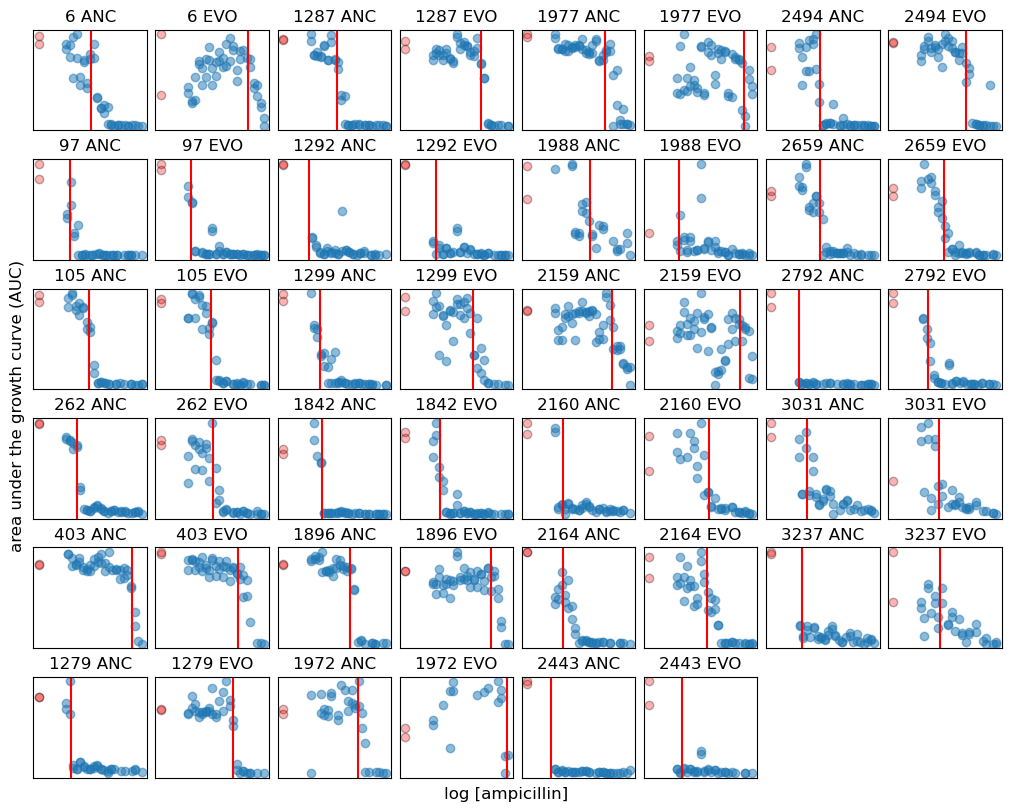

In [11]:
fig = plt.figure(figsize=(10, 8), constrained_layout=True)
fig.supxlabel("log [ampicillin]")
fig.supylabel("area under the growth curve (AUC)")

gs = fig.add_gridspec(6, 8)

for i, strn in enumerate(strns):
    supdf = data[data["strn"] == strn]
#    supdf = supdf.drop(supdf[supdf["AUC"] > 2000].index)
    
    for h, hist in enumerate(["ANC", "EVO"]):
        ax = fig.add_subplot(gs[i%6, (i//6) * 2 + h])
        df = supdf.loc[supdf["hist"] == hist]
        
        AUC0 = df.loc[df["camp"] == 0, "AUC"].mean()
        df = df.drop(df[df["AUC"] > AUC0 * 1.5].index)
        ax.scatter(df.loc[df["camp"] == 0].shape[0] * [-2], df.loc[df["camp"] == 0, "AUC"] / AUC0, c="r", ec="k", alpha=0.3)
        
        df = df.loc[df["camp"] != 0]
        xs = np.log10(df["camp"].values)
        ys = df["AUC"].values / AUC0
        IC50 = simple_IC50(xs, ys,)
        
        if (i == 0 and h == 0):
            IC50s = pd.DataFrame(IC50, index = [strn], columns=[hist])
        else:
            IC50s.loc[strn, hist] = IC50
        
        ax.scatter(xs, ys, alpha = 0.5)
        ax.axvline(IC50, c="r")
        ax.set(xticks=[], yticks=[], title = "{} {}".format(strn, hist), )#ylim=(0, 2000))
    
plt.show()

## Save pretreated data

In [10]:
IC50s.to_csv("{}/data/log10_IC50s.csv".format(cwd), sep=",",)